# Exercises XP: Evaluating LLMs for Summarization

## What you will learn
- Hands-on evaluation for summarization: accuracy vs. ROUGE.
- Strengths/weaknesses of metrics and model size comparisons.
- Using Hugging Face `transformers` + `evaluate` for quick experiments.
- Data loading, sampling, preprocessing, and debugging model outputs.

**Create**: evaluation scripts, comparison tables, custom metrics, and short analyses.

In [1]:
# Part I. Setup (run once per runtime)
!pip -q install rouge_score==0.1.2 evaluate datasets "transformers<5" accelerate nltk --quiet

import os
os.environ["USE_TF"] = "0"                 # transformers: PyTorch only
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

False

In [2]:
import time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, transformers, evaluate
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 200)
torch.manual_seed(0); random.seed(0); np.random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| transformers", transformers.__version__, "| evaluate", evaluate.__version__, "| device:", DEVICE)

torch 2.14.1+cpu | transformers 4.57.6 | evaluate 0.4.6 | device: cpu


### Part II. Dataset loading and exploration
Dataset: [abisee/cnn_dailymail](https://huggingface.co/datasets/abisee/cnn_dailymail), config `3.0.0`. We map `article` → `prompt_text` and `highlights` → `prompt_title`.

Instead of downloading the full dataset (≈ 1.3 GB), we use the **Hugging Face datasets-server API**, as suggested in the instructions. It returns pages of up to 100 rows, so we fetch a few pages at random offsets of the `train` and `test` splits and save them as `train.csv` and `test.csv`. Those two files are then loaded with pandas and sampled (100 train / 50 test). If the API is unreachable, the notebook falls back to `datasets.load_dataset(..., streaming=True)`.

In [3]:
import requests

API = "https://datasets-server.huggingface.co/rows"
DS = {"dataset": "abisee/cnn_dailymail", "config": "3.0.0"}

def fetch_split_to_csv(split, path, n_pages=3, page_size=100, seed=42):
    if os.path.exists(path):
        return
    rng = random.Random(seed)
    total = requests.get(API, params={**DS, "split": split, "offset": 0, "length": 1}, timeout=60).json()["num_rows_total"]
    rows = []
    for _ in range(n_pages):
        offset = rng.randrange(0, total - page_size)
        for attempt in range(4):
            try:
                r = requests.get(API, params={**DS, "split": split, "offset": offset, "length": page_size}, timeout=60)
                r.raise_for_status(); break
            except requests.RequestException:
                time.sleep(2 ** attempt)
        rows += [x["row"] for x in r.json()["rows"]]
    df = pd.DataFrame(rows).rename(columns={"article": "prompt_text", "highlights": "prompt_title"})
    df[["id", "prompt_text", "prompt_title"]].to_csv(path, index=False)
    print(f"{split}: {total} rows in the full split -> saved {len(df)} rows to {path}")

def fetch_with_datasets(split, path, n=300):
    from datasets import load_dataset
    ds = load_dataset("abisee/cnn_dailymail", "3.0.0", split=split, streaming=True)
    rows = [x for _, x in zip(range(n), ds)]
    pd.DataFrame(rows).rename(columns={"article": "prompt_text", "highlights": "prompt_title"})[["id", "prompt_text", "prompt_title"]].to_csv(path, index=False)

for split, path in [("train", "train.csv"), ("test", "test.csv")]:
    try:
        fetch_split_to_csv(split, path)
    except Exception as exc:
        print(f"datasets-server failed ({exc}); streaming with datasets instead")
        fetch_with_datasets(split, path)

datasets-server failed (HTTPSConnectionPool(host='datasets-server.huggingface.co', port=443): Read timed out. (read timeout=60)); streaming with datasets instead


test: 11490 rows in the full split -> saved 300 rows to test.csv


In [4]:
train_path = 'train.csv'
test_path = 'test.csv'

def load_and_sample(path, n, seed=42):
    df = pd.read_csv(path)
    return df.sample(min(n, len(df)), random_state=seed).reset_index(drop=True)

train_df = load_and_sample(train_path, 100)
test_df = load_and_sample(test_path, 50)

first = train_df.iloc[0]
print("ARTICLE (prompt_text):\n", first["prompt_text"][:1500], "...\n")
print("REFERENCE SUMMARY (prompt_title):\n", first["prompt_title"])

ARTICLE (prompt_text):
 BAGHDAD, Iraq (CNN)  -- Coalition troops killed the al Qaeda terrorist who masterminded the February 2006 attack on Samarra's al-Askariya mosque and set off continuing violence and reprisal killings between Sunnis and Shiites, the U.S. military said Sunday. The attack on Samarra's al-Askariya mosque set off violence between Sunnis and Shiites. Haitham Sabah al-Badri, the al Qaeda emir of greater Samarra, was killed by an airstrike Thursday east of Samarra, said Rear Adm. Mark Fox during a news conference. "Eliminating al-Badri is another step in breaking the cycle of violence instigated by the attack on the holy shrine in Samarra," Fox said. "We will continue to hunt down the brutal terrorists who are intent on creating a Taliban-like state in Iraq." Coalition forces Thursday raided four buildings outside Samarra that were associated with al-Badri, according to a U.S. military news release. During the raid, at least four armed men were seen leaving the buildings

In [5]:
print("Train sample:", train_df.shape, "| Test sample:", test_df.shape)
display(train_df)
display(test_df)

Train sample: (100, 3) | Test sample: (50, 3)


,id,prompt_text,prompt_title
0,cb4d9818866490b281e8f5529c9957ba366390e7,"BAGHDAD, Iraq (CNN) -- Coalition troops killed the al Qaeda terrorist who masterminded the February 2006 attack on Samarra's al-Askariya mosque and set off continuing violence and reprisal killin...",Haitham Sabah al-Badri was the al Qaeda emir of greater Samarra .\nU.S. military says al-Badri suspected in two other attacks that killed 49 .\nFamily of slain girl upset soldier wasn't sentenced ...
1,50e996059a005d15e3e89b5a3c3695309671ed34,(CNN) -- The Boeing 777 is the mainstay of many airlines' long-haul fleets and has never been involved in a fatal accident during its service history. British Airways aircrew fly the Royal Standar...,"The Boeing 777 aircraft first entered service on June 7, 1995 .\nFirst airplane U.S. (FAA) approved for extended-range twin-engine operations .\nEngineers designed, electronically pre-assembled th..."
2,59a9e7cad1c4c873738dda62b7e7b39bc2553710,"(CNN) -- Tens of thousands of Congolese refugees fled camps Tuesday in the Democratic Republic of Congo as rebel troops attacked government forces in the area, the U.N. refugee agency said. Refuge...","NEW: Congo rebels blame Rwandan Hutus for attack, report says .\nInternally displaced Congolese flee as rebels attack government troops .\nTorrential rain makes refugee movement difficult .\nU.N. ..."
3,613d6311ec2c1985bd44707d1796d275452fe156,"(CNN) -- Police and FBI agents are investigating the discovery of an empty rocket launcher tube on the front lawn of a Jersey City, New Jersey, home, FBI spokesman Sean Quinn said. Niranjan Desai ...","Empty anti-tank weapon turns up in front of New Jersey home .\nDevice handed over to Army ordnance disposal unit .\nWeapon not capable of being reloaded, experts say ."
4,0a37124fe35e31ae9fe8dd7715aeed88002e23e9,"WASHINGTON (CNN) -- President Bush's top adviser on homeland security is stepping down after 4½ years on the job, the White House said Monday. Fran Townsend served more than four years as homeland...",Fran Townsend says she'll look for opportunities in the private sector .\nTownsend has worked in government and law enforcement for 25 years .\nTownsend will be on a panel searching for a replacem...
...,...,...,...
95,bf0cd4ccacd4fe045995338f4c44d9cf18000226,"(CNN) -- At least 14 people were killed and 60 others wounded Thursday when a bomb ripped through a crowd waiting to see Algeria's president in Batna, east of the capital of Algiers, the Algerie P...",Bomb victims waiting for presidential visit .\nBlast went off 15 minutes before president's arrival .\nAlgeria faces Islamic insurgency .\nAl Qaeda-affiliated group claimed July attacks .
96,00359f516cdf8b1800c7102711bd9aa400d1c749,"LOS ANGELES, California (CNN) -- Former detainees of Immigration and Customs Enforcement accuse the agency in a lawsuit of forcibly injecting them with psychotropic drugs while trying to shuttle t...","Detainees file suit against ICE, allege they were injected with drugs .\nOne detainee tells CNN: ""What they did to me was very, very bad""\nICE says 1,073 detainees have had ""medical escorts"" since..."
97,d4474ce9da725c1540ac826f3247f53d086808fb,"(CNN) -- A bus hopped a highway median and crashed into a pickup truck before being broadsided by an 18-wheeler, Arkansas police said, killing the pickup driver and two bus riders. Two passengers ...","Bus driver, tractor-trailer trucker injured in 3-vehicle crash, AP reports .\nBus crossed median, hit pickup truck, then 18-wheeler, killing 3 .\nAll lanes of I-40 closed for 13 miles east of Forr..."
98,2757ff294ae08e977ed6a2b6e1854210f28f12c9,"LONDON, England (CNN) -- Princess Diana's relationships with two Muslim men provoked an outburst from her mother, who called her daughter ""a whore"", Paul Burrell, the princess's former butler, tol...","Paul Burrell, Princess Diana's former butler, gives evidence at inquest .\nDescribes phone call in which Diana's mother called her daughter""a whore""\nBurrell says Queen Eliza

,id,prompt_text,prompt_title
0,8921af9f1beb04d70e8e40f28292cfd09c7aad40,"Jerusalem (CNN)The flame of remembrance burns in Jerusalem, and a song of memory haunts Valerie Braham as it never has before. This year, Israel's Memorial Day commemoration is for bereaved family...","""We all share the same pain,"" Valerie Braham tells Memorial Day crowd in Israel .\nHer husband, Philippe Braham, was among 17 killed in January's terror attacks in Paris .\nFrench authorities foil..."
1,ccb37f6eba3568f515734a47646183b3fb27c998,"(CNN)Larry Johnson remembers the fear and feeling of helplessness from being on the SkyWest Airlines flight that made an emergency landing in Buffalo, New York. ""I thought we were done,"" he said T...",Three passengers report a loss of consciousness on SkyWest flight .\nBut officials say there is no evidence of a pressurization problem .
2,e8fd26eb7eeff757c31d0ea24b0257f9fd089b79,Tottenham are confident Kyle Walker has not broken his foot following a scan on Tuesday. There were fears the England defender may have fractured his right foot after taking a hefty blow from a co...,Tottenham full-back Kyle Walker sustained a foot injury following a collision with Burnley's Kieran Trippier during the draw at Turf Moor on Sunday .\nEarly fears that the foot was broken have bee...
3,1a2f81be8fcf453038e732ed7184730bea605f65,Renowned fashion designer Collette Dinnigan has placed her luxurious Paddington home on the market after splashing out on a stylish waterfront home in one of Sydney's most exclusive suburbs. The f...,Collette Dinnigan's Paddington $6 million home has hit the market .\nShe and her husband Bradley Cocks paid $4.45 million for it back in 2009 .\nThe luxury house will go under the hammer on May 23...
4,e8ad54eee05e92bde8f0b6f38bc310d631d23f00,"Los Angeles (CNN)She's one of the hottest and most successful Latinas in Hollywood, but now Sofia Vergara is playing defense in a legal battle initiated by her ex-fiance: He wants to keep the two ...","Loeb says he filed the lawsuit and doesn't want want money from his ""ex""\nNick Loeb reportedly wants to prevent Vergara from destroying the embryos .\nVergara spoke of freezing embryos with Loeb i..."
5,a4012b8e0b16ad5506d419743065933ad10e2066,"Boston (CNN)Adrianne Haslet-Davis and her husband, Adam Davis, were standing near the finish line on the day of the Boston Marathon bombing. Her feet were sore from wearing 4.5-inch heels. Still, ...",Jurors in sentencing phase in Dzhokhar Tsarnaev's trial hear of loss .\nVictims testify about the impact of the bombing on their lives .
6,30a1076c0b54e22627c3fb026cc374a71053703c,Jordan Spieth will continue his quest for Masters glory when he tees off his third round at Augusta at 2:55pm local time (7:55pm BST) on Saturday. The 21-year-old American holds a five-shot lead a...,Jordan Spieth and Charley Hoffman to tee off at 7:55pm UK time .\nJustin Rose in penultimate pairing at 7:45pm with Dustin Johnson .\nPaul Casey joined by Phil Mickelson at 7:35pm on Saturday .\n...
7,e0bdcc529cb7d9bd7655c0118f789ecfaaf9c8b6,"In true Zlatan Ibrahimovic style, he was not content with simply breaking the 100 goals barrier for Paris Saint-Germain on Wednesday evening. The 33-year-old added another two to make it a hat-tri...",Zlatan Ibrahimovic scored a hat-trick for PSG on Wednesday night .\nIt took his tally for the French club to 102 goals in less than three years .\nHe now trails only former Portugal forward Pedro...
8,f15b6b2708adde86aabeea3844a5d9d7b04d9479,"The adoptive grandparents of a Texas toddler who died after a brutal beating last month are speaking out against the boy's mother, who they say didn't do enough to protect her son from her boyfrie...","Adrian Langlais died on March 19, the day after his second birthday, from head injuries allegedly caused by his mother's boyfriend Christian Tyrrell .\nThe toddler's adoptive grandparents say they..."
9,2dfb2a214ba45ec28d03f536e5e37568b14c83b4,Alan Stubbs hailed the bravery of his Hibs p

In [6]:
stats = pd.DataFrame({
    "article words": train_df["prompt_text"].str.split().str.len(),
    "summary words": train_df["prompt_title"].str.split().str.len(),
    "summary sentences": train_df["prompt_title"].str.count("\n") + 1,
}).describe().round(1)
stats

,article words,summary words,summary sentences
count,100.0,100.0,100.0
mean,595.7,43.0,3.7
std,274.9,7.1,0.5
min,155.0,28.0,3.0
25%,355.0,38.8,3.0
50%,601.5,43.0,4.0
75%,752.5,48.2,4.0
max,1665.0,62.0,4.0


Articles average roughly 700 words, much longer than T5's 512-token input window and close to GPT-2's 1 024-token limit, so they will be **truncated**. Reference summaries (*highlights*) are 3–4 bullet sentences, roughly 50 words, written by journalists, separated by newlines and often **abstractive**: they rephrase rather than copy.

### Part III. Summarization with T5
- `batch_generator` yields mini-batches.
- `summarize_with_t5` uses `T5ForConditionalGeneration`, a GPU when one is available, the `"summarize: "` prefix, `generate()` and `decode(skip_special_tokens=True)`. It clears the CUDA cache and calls `gc.collect()` after each batch and at the end.

Generation settings are the same for every model: beam search with 4 beams, at most 64 new tokens (CNN/DM highlights are about 50 words), and `no_repeat_ngram_size=3` against loops.

In [7]:
import torch, gc
from transformers import AutoTokenizer, T5ForConditionalGeneration
from typing import Iterable, List

def batch_generator(items: List[str], batch_size: int):
    for i in range(0, len(items), batch_size):
        yield items[i:i + batch_size]

def summarize_with_t5(texts: List[str], model_name: str = 't5-small', batch_size: int = 4, max_new_tokens: int = 64):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = T5ForConditionalGeneration.from_pretrained(model_name).to(device).eval()
    summaries = []
    for batch in batch_generator(texts, batch_size):
        inputs = tokenizer(["summarize: " + t for t in batch], max_length=512, truncation=True,
                           padding=True, return_tensors="pt").to(device)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=4,
                                 no_repeat_ngram_size=3, early_stopping=True)
        summaries += tokenizer.batch_decode(out, skip_special_tokens=True)
        del inputs, out
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()
    return [s.strip() for s in summaries]

RUN_T5 = True
timings = {}
if RUN_T5:
    t0 = time.time()
    train_summaries_t5 = summarize_with_t5(train_df['prompt_text'].tolist(), model_name='t5-small', batch_size=4)
    timings["t5-small"] = time.time() - t0
    print(f"t5-small: {len(train_summaries_t5)} summaries in {timings['t5-small']:.0f}s")
    display(pd.DataFrame({
        'prompt_text': train_df['prompt_text'].str.slice(0, 200) + "...",
        'reference_summary': train_df['prompt_title'],
        't5_small_summary': train_summaries_t5
    }).head(10))
else:
    print("Skipping T5 generation for speed. Set RUN_T5=True to execute.")

t5-small: 100 summaries in 102s


,prompt_text,reference_summary,t5_small_summary
0,"BAGHDAD, Iraq (CNN) -- Coalition troops killed the al Qaeda terrorist who masterminded the February 2006 attack on Samarra's al-Askariya mosque and set off continuing violence and reprisal killin...",Haitham Sabah al-Badri was the al Qaeda emir of greater Samarra .\nU.S. military says al-Badri suspected in two other attacks that killed 49 .\nFamily of slain girl upset soldier wasn't sentenced ...,the al Qaeda emir of greater Samarra was killed by an airstrike. the attack on Samarra's al-Askariya mosque set off violence between sunnis and Shiites. al-Badri is believed to have been involved ...
1,(CNN) -- The Boeing 777 is the mainstay of many airlines' long-haul fleets and has never been involved in a fatal accident during its service history. British Airways aircrew fly the Royal Standar...,"The Boeing 777 aircraft first entered service on June 7, 1995 .\nFirst airplane U.S. (FAA) approved for extended-range twin-engine operations .\nEngineers designed, electronically pre-assembled th...","the 777 is the mainstay of many airlines' long-haul fleets. the aircraft first entered service on June 7, 1995. more than 900 suppliers from 17 countries came together to provide parts."
2,"(CNN) -- Tens of thousands of Congolese refugees fled camps Tuesday in the Democratic Republic of Congo as rebel troops attacked government forces in the area, the U.N. refugee agency said. Refuge...","NEW: Congo rebels blame Rwandan Hutus for attack, report says .\nInternally displaced Congolese flee as rebels attack government troops .\nTorrential rain makes refugee movement difficult .\nU.N. ...","tens of thousands of Congolese refugees fled camps in the Democratic Republic of Congo. rebel troops attacked government forces in the area, the u.n. refugee agency says. a spokesman for the milit..."
3,"(CNN) -- Police and FBI agents are investigating the discovery of an empty rocket launcher tube on the front lawn of a Jersey City, New Jersey, home, FBI spokesman Sean Quinn said. Niranjan Desai ...","Empty anti-tank weapon turns up in front of New Jersey home .\nDevice handed over to Army ordnance disposal unit .\nWeapon not capable of being reloaded, experts say .","the 20-year-old AT4 anti-tank rocket launcher tube was found on her lawn. the device has been turned over to the 754th Ordnance Company, an explosive disposal unit. a neighbor says the object look..."
4,"WASHINGTON (CNN) -- President Bush's top adviser on homeland security is stepping down after 4½ years on the job, the White House said Monday. Fran Townsend served more than four years as homeland...",Fran Townsend says she'll look for opportunities in the private sector .\nTownsend has worked in government and law enforcement for 25 years .\nTownsend will be on a panel searching for a replacem...,"homeland security Adviser Fran Townsend is stepping down after 412 years on the job. she will look for new opportunities outside government, the white house says. townsend has spent 25 years worki..."
5,"(CNN) -- A Florida judge Friday handed a legal victory to a former astronaut accused of assaulting a romantic rival, ruling evidence found in her car and statements she made to police after her ar...",Judge: Lisa Nowak's statements and items in her car were unlawfully obtained .\nNowak's attorneys have said her comments were made under duress .\nFormer astronaut is accused of stalking and assau...,"new: judge rules that all were unlawfully obtained. new: ""in each and every case, this court must ensure that the constitutional protections are scrupulously honored,"" judge says. nowak is accused..."
6,WASHINGTON (CNN) -- U.S. Coast Guard planes and ships were searching Friday for a Japanese balloonist who disappeared off the Alaska coast while flying from Japan to the west coast United States. ...,Balloonist Michio Kanda missing on flight from Japan to U.S.\nU.S. Coast Guard searching area around his last known position .\nKanda holds the world record 

### Part IV. Accuracy evaluation (toy, likely near zero)
Naive accuracy = the share of generated summaries that are an **exact string match** with the reference.

In [8]:
from typing import List

def compute_accuracy(preds: List[str], refs: List[str]) -> float:
    matches = sum(1 for p, r in zip(preds, refs) if p.strip() == r.strip())
    return matches / max(len(refs), 1)

if 'train_summaries_t5' in locals():
    acc = compute_accuracy(train_summaries_t5, train_df['prompt_title'].tolist())
    print(f"Exact-match accuracy: {acc:.4f}")
    # even a 'perfect copy' of the reference sentences fails if only the line breaks differ
    refs = train_df['prompt_title'].tolist()
    print("Accuracy of the references against themselves with newlines replaced by spaces:",
          compute_accuracy([r.replace("\n", " ") for r in refs], refs))
    # token-level 'accuracy': position-by-position word match (also meaningless for free text)
    tok_acc = np.mean([np.mean([a == b for a, b in zip(p.lower().split(), r.lower().split())] or [0])
                       for p, r in zip(train_summaries_t5, refs)])
    print(f"Position-wise word accuracy: {tok_acc:.4f}")
else:
    print("Accuracy skipped (no predictions).")

Exact-match accuracy: 0.0000
Accuracy of the references against themselves with newlines replaced by spaces: 0.0
Position-wise word accuracy: 0.0229


**Why accuracy is (almost) zero.** Summarization is open-ended: there are many valid summaries of an article, and the reference is only one of them. An exact match requires the same words, in the same order, with the same punctuation and line breaks. Even the references themselves score **0** once their newlines are replaced by spaces.

A position-wise word match is no better: inserting one word shifts everything after it. Accuracy gives no partial credit and therefore cannot rank models. We need an **overlap-based** metric: ROUGE.

### Part V. ROUGE metric implementation
**ROUGE** (Recall-Oriented Understudy for Gisting Evaluation) counts the n-grams shared by the candidate and the reference summary:
- **ROUGE-N**: overlap of n-grams. ROUGE-1 counts single words (content), ROUGE-2 counts bigrams (fluency and phrasing).
- **ROUGE-L**: the longest common subsequence (word order, without requiring contiguity).
- **ROUGE-Lsum**: ROUGE-L computed *per sentence* and then combined. It needs the sentences to be separated by **newlines**.

For each variant we get precision (overlap / candidate n-grams), recall (overlap / reference n-grams) and F1; `evaluate` reports the F1.

**Preprocessing.** Model outputs are single strings with no line breaks. We split them into sentences with NLTK's `sent_tokenize` and join the sentences with `"\n"`, so that `rougeLsum` sees the sentence boundaries. ⚠️ The template's `normalize_text` joined the sentences with `""`, which glues the last word of one sentence to the first word of the next (`"sat.The"`) and breaks `rougeLsum`; we fix it below.

In [9]:
import evaluate
from nltk.tokenize import sent_tokenize
from typing import List

rouge = evaluate.load('rouge')

def normalize_text(text):
    sents = sent_tokenize(str(text).strip())
    return "\n".join(sents)          # one sentence per line (needed by rougeLsum)

def compute_rouge_score(preds: List[str], refs: List[str], use_stemmer: bool = True, use_aggregator: bool = True):
    preds = [normalize_text(p) for p in preds]
    refs = [normalize_text(r) for r in refs]
    scores = rouge.compute(predictions=preds, references=refs, use_stemmer=use_stemmer, use_aggregator=use_aggregator)
    return {k: (round(float(v), 4) if use_aggregator else [round(float(x), 4) for x in v]) for k, v in scores.items()}

# Smoke test with identical strings and empty prediction
test_preds = ["alpha beta", "", "The cat sat."]
test_refs  = ["alpha beta", "reference text", "The cat sat."]
print("ROUGE sanity check:")
print("  aggregated:", compute_rouge_score(test_preds, test_refs))
print("  per pair  :", compute_rouge_score(test_preds, test_refs, use_aggregator=False))
print("\nnormalize_text example:", repr(normalize_text("The cat sat. The dog ran away! Did it?")))

ROUGE sanity check:


  aggregated: {'rouge1': 0.6667, 'rouge2': 0.6667, 'rougeL': 0.6667, 'rougeLsum': 0.6667}
  per pair  : {'rouge1': [1.0, 0.0, 1.0], 'rouge2': [1.0, 0.0, 1.0], 'rougeL': [1.0, 0.0, 1.0], 'rougeLsum': [1.0, 0.0, 1.0]}

normalize_text example: 'The cat sat.\nThe dog ran away!\nDid it?'


### Part VI. Understanding ROUGE scores

In [10]:
refs = train_df["prompt_title"].tolist()

# 1. Exact match
print("1) predictions == references :", compute_rouge_score(refs, refs))

# 2. Null predictions
print("2) empty predictions          :", compute_rouge_score([""] * len(refs), refs))

# 3. Stemming
pairs = [("The kids were running fast", "The kid runs fast"),
         ("Prices increased sharply", "The price increases sharply")]
for p, r in pairs:
    print(f"3) {p!r} vs {r!r}: no stemmer {compute_rouge_score([p], [r], use_stemmer=False)['rouge1']}"
          f"  | with stemmer {compute_rouge_score([p], [r], use_stemmer=True)['rouge1']}  (ROUGE-1 F1)")

1) predictions == references : {'rouge1': 1.0, 'rouge2': 1.0, 'rougeL': 1.0, 'rougeLsum': 1.0}
2) empty predictions          : {'rouge1': 0.0, 'rouge2': 0.0, 'rougeL': 0.0, 'rougeLsum': 0.0}


3) 'The kids were running fast' vs 'The kid runs fast': no stemmer 0.4444  | with stemmer 0.8889  (ROUGE-1 F1)
3) 'Prices increased sharply' vs 'The price increases sharply': no stemmer 0.2857  | with stemmer 0.8571  (ROUGE-1 F1)


In [11]:
# 4. N-gram analysis: increasing overlap with a reference sentence
reference = "the quick brown fox jumps over the lazy dog"
candidates = {
    "identical": "the quick brown fox jumps over the lazy dog",
    "same words, shuffled": "dog lazy the over jumps fox brown quick the",
    "one word changed": "the quick brown fox leaps over the lazy dog",
    "half the sentence": "the quick brown fox",
    "synonyms": "a fast auburn fox hops above a sleepy hound",
    "unrelated": "stock markets fell sharply on monday morning",
}
ngram_df = pd.DataFrame({name: compute_rouge_score([c], [reference], use_stemmer=False) for name, c in candidates.items()}).T
ngram_df

,rouge1,rouge2,rougeL,rougeLsum
identical,1.0000,1.0000,1.0000,1.0000
"same words, shuffled",1.0000,0.0000,0.3333,0.3333
one word changed,0.8889,0.7500,0.8889,0.8889
half the sentence,0.6154,0.5455,0.6154,0.6154
synonyms,0.1111,0.0000,0.1111,0.1111
unrelated,0.0000,0.0000,0.0000,0.0000


In [12]:
# 5. Symmetry: swapping predictions and references
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

a = "the quick brown fox"
b = "the quick brown fox jumps over the lazy dog"
s_ab, s_ba = scorer.score(target=b, prediction=a), scorer.score(target=a, prediction=b)
sym = pd.DataFrame({
    "pred=short, ref=long (P/R/F)": {k: tuple(round(x, 3) for x in v) for k, v in s_ab.items()},
    "pred=long, ref=short (P/R/F)": {k: tuple(round(x, 3) for x in v) for k, v in s_ba.items()},
})
display(sym)
print("evaluate (F1) a->b:", compute_rouge_score([a], [b]), "\nevaluate (F1) b->a:", compute_rouge_score([b], [a]))

# on real data: t5-small summaries vs references, and swapped
if 'train_summaries_t5' in locals():
    print("\nt5-small vs refs :", compute_rouge_score(train_summaries_t5, refs))
    print("refs vs t5-small :", compute_rouge_score(refs, train_summaries_t5))

,"pred=short, ref=long (P/R/F)","pred=long, ref=short (P/R/F)"
rouge1,"(1.0, 0.444, 0.615)","(0.444, 1.0, 0.615)"
rouge2,"(1.0, 0.375, 0.545)","(0.375, 1.0, 0.545)"
rougeL,"(1.0, 0.444, 0.615)","(0.444, 1.0, 0.615)"


evaluate (F1) a->b: {'rouge1': 0.6154, 'rouge2': 0.5455, 'rougeL': 0.6154, 'rougeLsum': 0.6154} 
evaluate (F1) b->a: {'rouge1': 0.6154, 'rouge2': 0.5455, 'rougeL': 0.6154, 'rougeLsum': 0.6154}



t5-small vs refs : {'rouge1': 0.3149, 'rouge2': 0.12, 'rougeL': 0.219, 'rougeLsum': 0.2931}


refs vs t5-small : {'rouge1': 0.3149, 'rouge2': 0.12, 'rougeL': 0.219, 'rougeLsum': 0.2929}


#### Findings on ROUGE
1. **Exact match → 1.0 and empty prediction → 0.0** for every variant. These are the two ends of the scale (no NaN for empty strings with `evaluate`).
2. **Stemming matters.** *"The kids were running fast"* vs *"The kid runs fast"* goes from **0.44 → 0.89** ROUGE-1 once `kids/kid` and `running/runs` are reduced to the same stem, and *"Prices increased sharply"* vs *"The price increases sharply"* from 0.29 → 0.86. Without stemming, ROUGE punishes simple inflection, which is why `use_stemmer=True` is the usual choice.
3. **The n-gram order captures different things.**
   - *Shuffled words* keep **ROUGE-1 = 1.0** but **ROUGE-2 = 0.0** (ROUGE-L 0.33): ROUGE-1 measures content only, while ROUGE-2 and ROUGE-L also reward word order and fluency.
   - *One word changed* costs more in ROUGE-2 (0.75) than in ROUGE-1 (0.89), because one changed word breaks two bigrams.
   - *Half the sentence* gives P = 1 and R = 0.44, hence F1 = 0.62.
   - **Synonyms score almost nothing** (0.11): *"a fast auburn fox hops above a sleepy hound"* means the same thing, but ROUGE only counts surface word overlap and has no notion of meaning.
4. **Symmetry.** Swapping prediction and reference **swaps precision and recall** (1.0/0.444 ↔ 0.444/1.0), so the **F1 is identical**: 0.615 both ways, and 0.3149 for t5-small vs refs in both directions. Since `evaluate` reports F1, it is symmetric. The tiny difference in `rougeLsum` (0.2931 vs 0.2929) comes from its sentence-level matching, which is not perfectly symmetric.

### Part VII. Comparing small and large models
- `t5-small` (60 M parameters) and `t5-base` (220 M) are encoder-decoder models. During pre-training they saw CNN/DailyMail with the `summarize:` prefix, so they are trained summarizers.
- `gpt2` (124 M) is a decoder-only language model that was **never trained to summarize**. Following the GPT-2 paper, we prompt it with `article + "\nTL;DR:"`.

GPT-2 has a hard context limit of 1 024 tokens (prompt + generated tokens). We truncate the article from the left side of the budget (we keep its beginning) so that `article + "TL;DR:" + max_new_tokens ≤ 1024`, pad on the left for batched generation, and keep only the newly generated tokens.

We also add the classic **Lead-3 baseline** (the first 3 sentences of the article), which is famously hard to beat on CNN/DM.

In [13]:
from transformers import AutoModelForCausalLM, AutoTokenizer

def summarize_with_gpt2(texts: List[str], model_name: str = 'gpt2', batch_size: int = 2, max_new_tokens: int = 64):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    tokenizer.pad_token = tokenizer.eos_token          # GPT-2 has no pad token
    tokenizer.padding_side = "left"                    # decoder-only: pad on the left for batched generation
    model = AutoModelForCausalLM.from_pretrained(model_name).to(device).eval()

    suffix = "\nTL;DR:"
    suffix_ids = tokenizer(suffix)["input_ids"]
    max_article = model.config.n_positions - max_new_tokens - len(suffix_ids)    # 1024 - 64 - 4 tokens
    summaries = []
    for batch in batch_generator(texts, batch_size):
        prompts = []
        for t in batch:
            ids = tokenizer(t)["input_ids"][:max_article]                          # keep the beginning of the article
            prompts.append(tokenizer.decode(ids) + suffix)
        inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=4, no_repeat_ngram_size=3,
                                 early_stopping=True, pad_token_id=tokenizer.eos_token_id)
        new_tokens = out[:, inputs["input_ids"].shape[1]:]                         # drop the prompt
        for s in tokenizer.batch_decode(new_tokens, skip_special_tokens=True):
            s = s.strip().split("\n\n")[0].strip()                                  # stop at the first blank line
            summaries.append(s)
        del inputs, out
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()
    del model
    gc.collect()
    return summaries

def lead_3(texts):
    return [" ".join(sent_tokenize(t)[:3]) for t in texts]

def compute_rouge_per_row(df: pd.DataFrame, pred_col: str, ref_col: str = 'prompt_title'):
    scores = compute_rouge_score(df[pred_col].fillna("").tolist(), df[ref_col].tolist(), use_aggregator=False)
    out = df.copy()
    for metric, values in scores.items():
        out[f"{pred_col}_{metric}"] = values
    return out

In [14]:
RUN_COMPARE = True
if RUN_COMPARE and 'train_summaries_t5' in locals():
    articles = train_df["prompt_text"].tolist()
    results_df = train_df.copy()
    results_df["t5-small"] = train_summaries_t5

    t0 = time.time(); results_df["t5-base"] = summarize_with_t5(articles, model_name="t5-base", batch_size=4); timings["t5-base"] = time.time() - t0
    t0 = time.time(); results_df["gpt2"] = summarize_with_gpt2(articles, model_name="gpt2", batch_size=2); timings["gpt2"] = time.time() - t0
    t0 = time.time(); results_df["lead-3"] = lead_3(articles); timings["lead-3"] = time.time() - t0
    print({k: f"{v:.0f}s" for k, v in timings.items()})

    MODELS = ["t5-small", "t5-base", "gpt2", "lead-3"]
    rouge_scores = {m: compute_rouge_score(results_df[m].tolist(), results_df["prompt_title"].tolist()) for m in MODELS}
    for m, s in rouge_scores.items():
        print(f"{m:9s} {s}")

{'t5-small': '102s', 't5-base': '281s', 'gpt2': '774s', 'lead-3': '0s'}


t5-small  {'rouge1': 0.3149, 'rouge2': 0.12, 'rougeL': 0.219, 'rougeLsum': 0.2931}
t5-base   {'rouge1': 0.3579, 'rouge2': 0.1532, 'rougeL': 0.2562, 'rougeLsum': 0.3338}
gpt2      {'rouge1': 0.1952, 'rouge2': 0.033, 'rougeL': 0.1322, 'rougeLsum': 0.1776}
lead-3    {'rouge1': 0.3201, 'rouge2': 0.1267, 'rougeL': 0.2042, 'rougeLsum': 0.2933}


In [15]:
# Per-row ROUGE for each model
per_row = results_df[["prompt_title"] + MODELS].copy()
for m in MODELS:
    per_row = compute_rouge_per_row(per_row, pred_col=m)
for m in MODELS:
    print(f"--- {m}")
    display(per_row[["prompt_title", m, f"{m}_rouge1", f"{m}_rouge2", f"{m}_rougeL"]].head(5))

--- t5-small


,prompt_title,t5-small,t5-small_rouge1,t5-small_rouge2,t5-small_rougeL
0,Haitham Sabah al-Badri was the al Qaeda emir of greater Samarra .\nU.S. military says al-Badri suspected in two other attacks that killed 49 .\nFamily of slain girl upset soldier wasn't sentenced ...,the al Qaeda emir of greater Samarra was killed by an airstrike. the attack on Samarra's al-Askariya mosque set off violence between sunnis and Shiites. al-Badri is believed to have been involved ...,0.3956,0.1798,0.2857
1,"The Boeing 777 aircraft first entered service on June 7, 1995 .\nFirst airplane U.S. (FAA) approved for extended-range twin-engine operations .\nEngineers designed, electronically pre-assembled th...","the 777 is the mainstay of many airlines' long-haul fleets. the aircraft first entered service on June 7, 1995. more than 900 suppliers from 17 countries came together to provide parts.",0.2785,0.2078,0.2532
2,"NEW: Congo rebels blame Rwandan Hutus for attack, report says .\nInternally displaced Congolese flee as rebels attack government troops .\nTorrential rain makes refugee movement difficult .\nU.N. ...","tens of thousands of Congolese refugees fled camps in the Democratic Republic of Congo. rebel troops attacked government forces in the area, the u.n. refugee agency says. a spokesman for the milit...",0.3750,0.1282,0.2250
3,"Empty anti-tank weapon turns up in front of New Jersey home .\nDevice handed over to Army ordnance disposal unit .\nWeapon not capable of being reloaded, experts say .","the 20-year-old AT4 anti-tank rocket launcher tube was found on her lawn. the device has been turned over to the 754th Ordnance Company, an explosive disposal unit. a neighbor says the object look...",0.2778,0.0857,0.2500
4,Fran Townsend says she'll look for opportunities in the private sector .\nTownsend has worked in government and law enforcement for 25 years .\nTownsend will be on a panel searching for a replacem...,"homeland security Adviser Fran Townsend is stepping down after 412 years on the job. she will look for new opportunities outside government, the white house says. townsend has spent 25 years worki...",0.5714,0.1765,0.3714


--- t5-base


,prompt_title,t5-base,t5-base_rouge1,t5-base_rouge2,t5-base_rougeL
0,Haitham Sabah al-Badri was the al Qaeda emir of greater Samarra .\nU.S. military says al-Badri suspected in two other attacks that killed 49 .\nFamily of slain girl upset soldier wasn't sentenced ...,"al Qaeda emir of greater Samarra killed by airstrike, military says . al-Badri masterminded 2006 attack on mosque in Samarra . attack set off violence between sunnis and Shiites .",0.3500,0.2051,0.3250
1,"The Boeing 777 aircraft first entered service on June 7, 1995 .\nFirst airplane U.S. (FAA) approved for extended-range twin-engine operations .\nEngineers designed, electronically pre-assembled th...","the Boeing 777 first entered service on June 7, 1995 . the aircraft seats between 301 and 368 passengers in a three-class configuration . it can fly distances up to 17,500 kilometers .",0.3797,0.2078,0.3544
2,"NEW: Congo rebels blame Rwandan Hutus for attack, report says .\nInternally displaced Congolese flee as rebels attack government troops .\nTorrential rain makes refugee movement difficult .\nU.N. ...","internally displaced people flee camps as rebel troops attack government forces . road to goma, about 10 miles from camps, crowded with refugees fleeing fighting . rebel spokesman denies allegatio...",0.4324,0.1111,0.2432
3,"Empty anti-tank weapon turns up in front of New Jersey home .\nDevice handed over to Army ordnance disposal unit .\nWeapon not capable of being reloaded, experts say .",a 20-year-old anti-tank rocket launcher tube was found on a home's lawn . the launcher is no longer operable and not considered a hazard to public safety . police and FBI agents are investigating ...,0.2029,0.0299,0.1449
4,Fran Townsend says she'll look for opportunities in the private sector .\nTownsend has worked in government and law enforcement for 25 years .\nTownsend will be on a panel searching for a replacem...,"""i'm going to just take another job doing 20-hour days,"" says Fran Townsend . ""we are safer today because of her leadership,"" president says . townsend has spent 25 years working in law enforcemen...",0.3768,0.1493,0.2609


--- gpt2


,prompt_title,gpt2,gpt2_rouge1,gpt2_rouge2,gpt2_rougeL
0,Haitham Sabah al-Badri was the al Qaeda emir of greater Samarra .\nU.S. military says al-Badri suspected in two other attacks that killed 49 .\nFamily of slain girl upset soldier wasn't sentenced ...,"Al Qaeda's leader Abu Bakr al-Baghdadi was killed in an airstrike by coalition forces in Iraq on Friday, the Pentagon said.",0.2400,0.0548,0.1867
1,"The Boeing 777 aircraft first entered service on June 7, 1995 .\nFirst airplane U.S. (FAA) approved for extended-range twin-engine operations .\nEngineers designed, electronically pre-assembled th...","The Boeing 787 Dreamliner is the world's longest-haul commercial airliner. It is the second-longest-haul airliner in the world, after the Airbus A320. The 787 is the first commercial airliner to b...",0.1633,0.0208,0.1224
2,"NEW: Congo rebels blame Rwandan Hutus for attack, report says .\nInternally displaced Congolese flee as rebels attack government troops .\nTorrential rain makes refugee movement difficult .\nU.N. ...","The U.S. government is trying to get rid of the Congo government, and it's not going to be easy.\nThe United States and the European Union are trying to find a way out of the crisis, but there's n...",0.0833,0.0000,0.0417
3,"Empty anti-tank weapon turns up in front of New Jersey home .\nDevice handed over to Army ordnance disposal unit .\nWeapon not capable of being reloaded, experts say .",An AT4 Anti-Tank Rocket Launcher Tube Found on the Front Lawn of a New Jersey Home,0.3111,0.1395,0.3111
4,Fran Townsend says she'll look for opportunities in the private sector .\nTownsend has worked in government and law enforcement for 25 years .\nTownsend will be on a panel searching for a replacem...,"Fran Townsend is leaving the Bush White House to become a private attorney general. She will be replaced by a new chief of staff, who will be appointed by the new administration.",0.3077,0.0635,0.2154


--- lead-3


,prompt_title,lead-3,lead-3_rouge1,lead-3_rouge2,lead-3_rougeL
0,Haitham Sabah al-Badri was the al Qaeda emir of greater Samarra .\nU.S. military says al-Badri suspected in two other attacks that killed 49 .\nFamily of slain girl upset soldier wasn't sentenced ...,"BAGHDAD, Iraq (CNN) -- Coalition troops killed the al Qaeda terrorist who masterminded the February 2006 attack on Samarra's al-Askariya mosque and set off continuing violence and reprisal killin...",0.3235,0.1642,0.1912
1,"The Boeing 777 aircraft first entered service on June 7, 1995 .\nFirst airplane U.S. (FAA) approved for extended-range twin-engine operations .\nEngineers designed, electronically pre-assembled th...",(CNN) -- The Boeing 777 is the mainstay of many airlines' long-haul fleets and has never been involved in a fatal accident during its service history. British Airways aircrew fly the Royal Standar...,0.2540,0.1774,0.2222
2,"NEW: Congo rebels blame Rwandan Hutus for attack, report says .\nInternally displaced Congolese flee as rebels attack government troops .\nTorrential rain makes refugee movement difficult .\nU.N. ...","(CNN) -- Tens of thousands of Congolese refugees fled camps Tuesday in the Democratic Republic of Congo as rebel troops attacked government forces in the area, the U.N. refugee agency said. Refuge...",0.3415,0.0992,0.1626
3,"Empty anti-tank weapon turns up in front of New Jersey home .\nDevice handed over to Army ordnance disposal unit .\nWeapon not capable of being reloaded, experts say .","(CNN) -- Police and FBI agents are investigating the discovery of an empty rocket launcher tube on the front lawn of a Jersey City, New Jersey, home, FBI spokesman Sean Quinn said. Niranjan Desai ...",0.2982,0.1071,0.2281
4,Fran Townsend says she'll look for opportunities in the private sector .\nTownsend has worked in government and law enforcement for 25 years .\nTownsend will be on a panel searching for a replacem...,"WASHINGTON (CNN) -- President Bush's top adviser on homeland security is stepping down after 4½ years on the job, the White House said Monday. Fran Townsend served more than four years as homeland...",0.2979,0.0652,0.1702


### Part VIII. Comparing all models

In [16]:
import pandas as pd

def compare_models(rouge_dict):
    # {model_name: rouge_scores_dict} -> DataFrame (one row per model), sorted by ROUGE-L
    return pd.DataFrame(rouge_dict).T.sort_values("rougeL", ascending=False)

def compare_models_summaries(df: pd.DataFrame, pred_cols: list):
    return df[["prompt_title"] + pred_cols].rename(columns={"prompt_title": "reference"})

comparison = compare_models(rouge_scores)
comparison["avg words"] = [results_df[m].str.split().str.len().mean().round(1) for m in comparison.index]
comparison["time / article (s)"] = [round(timings[m] / len(results_df), 3) for m in comparison.index]
display(comparison)
display(compare_models_summaries(results_df, MODELS).head(8))

,rouge1,rouge2,rougeL,rougeLsum,avg words,time / article (s)
t5-base,0.3579,0.1532,0.2562,0.3338,40.4,2.808
t5-small,0.3149,0.1200,0.2190,0.2931,39.4,1.025
lead-3,0.3201,0.1267,0.2042,0.2933,68.5,0.000
gpt2,0.1952,0.0330,0.1322,0.1776,43.5,7.745


,reference,t5-small,t5-base,gpt2,lead-3
0,Haitham Sabah al-Badri was the al Qaeda emir of greater Samarra .\nU.S. military says al-Badri suspected in two other attacks that killed 49 .\nFamily of slain girl upset soldier wasn't sentenced ...,the al Qaeda emir of greater Samarra was killed by an airstrike. the attack on Samarra's al-Askariya mosque set off violence between sunnis and Shiites. al-Badri is believed to have been involved ...,"al Qaeda emir of greater Samarra killed by airstrike, military says . al-Badri masterminded 2006 attack on mosque in Samarra . attack set off violence between sunnis and Shiites .","Al Qaeda's leader Abu Bakr al-Baghdadi was killed in an airstrike by coalition forces in Iraq on Friday, the Pentagon said.","BAGHDAD, Iraq (CNN) -- Coalition troops killed the al Qaeda terrorist who masterminded the February 2006 attack on Samarra's al-Askariya mosque and set off continuing violence and reprisal killin..."
1,"The Boeing 777 aircraft first entered service on June 7, 1995 .\nFirst airplane U.S. (FAA) approved for extended-range twin-engine operations .\nEngineers designed, electronically pre-assembled th...","the 777 is the mainstay of many airlines' long-haul fleets. the aircraft first entered service on June 7, 1995. more than 900 suppliers from 17 countries came together to provide parts.","the Boeing 777 first entered service on June 7, 1995 . the aircraft seats between 301 and 368 passengers in a three-class configuration . it can fly distances up to 17,500 kilometers .","The Boeing 787 Dreamliner is the world's longest-haul commercial airliner. It is the second-longest-haul airliner in the world, after the Airbus A320. The 787 is the first commercial airliner to b...",(CNN) -- The Boeing 777 is the mainstay of many airlines' long-haul fleets and has never been involved in a fatal accident during its service history. British Airways aircrew fly the Royal Standar...
2,"NEW: Congo rebels blame Rwandan Hutus for attack, report says .\nInternally displaced Congolese flee as rebels attack government troops .\nTorrential rain makes refugee movement difficult .\nU.N. ...","tens of thousands of Congolese refugees fled camps in the Democratic Republic of Congo. rebel troops attacked government forces in the area, the u.n. refugee agency says. a spokesman for the milit...","internally displaced people flee camps as rebel troops attack government forces . road to goma, about 10 miles from camps, crowded with refugees fleeing fighting . rebel spokesman denies allegatio...","The U.S. government is trying to get rid of the Congo government, and it's not going to be easy.\nThe United States and the European Union are trying to find a way out of the crisis, but there's n...","(CNN) -- Tens of thousands of Congolese refugees fled camps Tuesday in the Democratic Republic of Congo as rebel troops attacked government forces in the area, the U.N. refugee agency said. Refuge..."
3,"Empty anti-tank weapon turns up in front of New Jersey home .\nDevice handed over to Army ordnance disposal unit .\nWeapon not capable of being reloaded, experts say .","the 20-year-old AT4 anti-tank rocket launcher tube was found on her lawn. the device has been turned over to the 754th Ordnance Company, an explosive disposal unit. a neighbor says the object look...",a 20-year-old anti-tank rocket launcher tube was found on a home's lawn . the launcher is no longer operable and not considered a hazard to public safety . police and FBI agents are investigating ...,An AT4 Anti-Tank Rocket Launcher Tube Found on the Front Lawn of a New Jersey Home,"(CNN) -- Police and FBI agents are investigating the discovery of an empty rocket launcher tube on the front lawn of a Jersey City, New Jersey, home, FBI spokesman Sean Quinn said. Niranjan Desai ..."
4,Fran Townsend says she'll look for opportunities in the private sector .\nTownsend has worked in government and law enforcement for 25 years .\nTownsend will be on a panel searching for a replace

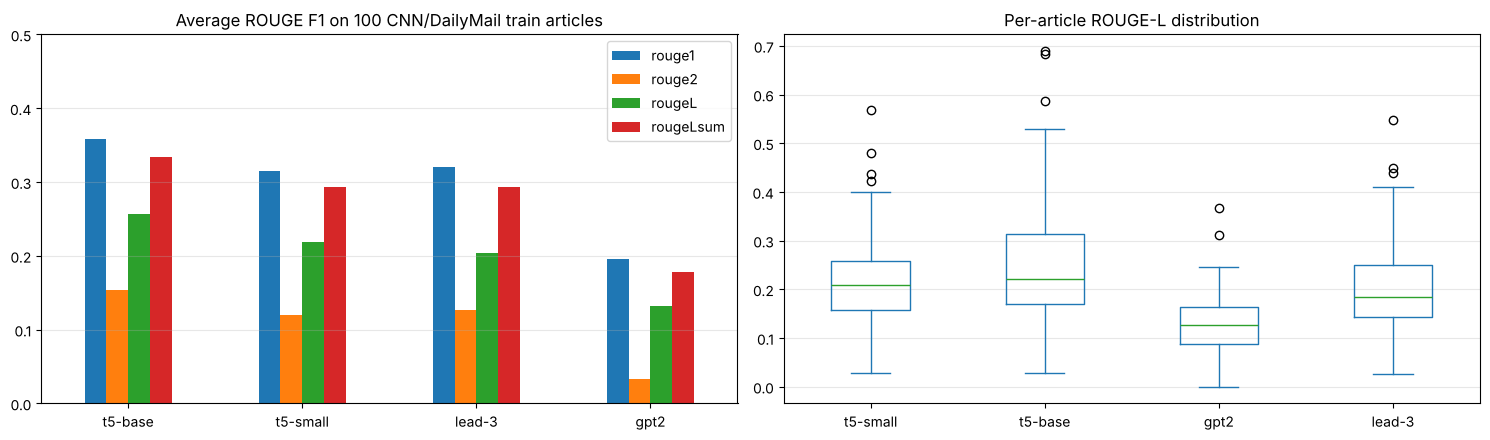

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
comparison[["rouge1", "rouge2", "rougeL", "rougeLsum"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Average ROUGE F1 on 100 CNN/DailyMail train articles"); axes[0].set_ylim(0, 0.5); axes[0].grid(axis="y", alpha=.3)
per_row[[f"{m}_rougeL" for m in MODELS]].rename(columns=lambda c: c.replace("_rougeL", "")).plot.box(ax=axes[1])
axes[1].set_title("Per-article ROUGE-L distribution"); axes[1].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

#### Modified accuracy metrics for summarization
Exact-match accuracy is useless, but we can make "accuracy" meaningful by turning it into a *pass rate*: a summary counts as correct if it is "good enough". We use two variants:
- **ROUGE-L ≥ τ**: the share of summaries whose ROUGE-L F1 reaches a threshold τ;
- **keyword recall accuracy**: the share of summaries that contain at least half of the reference's content words (no stopwords, stemmed).

In [18]:
from nltk.stem import PorterStemmer
from nltk.corpus import stopwords
nltk.download("stopwords", quiet=True)
_stem, _stop = PorterStemmer(), set(stopwords.words("english"))

def content_words(text):
    return {_stem.stem(w) for w in nltk.word_tokenize(str(text).lower()) if w.isalnum() and w not in _stop}

def threshold_accuracy(rouge_l_values, tau=0.3):
    return float(np.mean(np.array(rouge_l_values) >= tau))

def keyword_recall_accuracy(preds, refs, min_recall=0.5):
    hits = [len(content_words(p) & content_words(r)) / max(len(content_words(r)), 1) >= min_recall for p, r in zip(preds, refs)]
    return float(np.mean(hits))

custom = pd.DataFrame({
    m: {"exact-match acc": compute_accuracy(results_df[m].tolist(), results_df["prompt_title"].tolist()),
        "acc (ROUGE-L ≥ 0.2)": threshold_accuracy(per_row[f"{m}_rougeL"], 0.2),
        "acc (ROUGE-L ≥ 0.3)": threshold_accuracy(per_row[f"{m}_rougeL"], 0.3),
        "keyword-recall acc (≥50%)": keyword_recall_accuracy(results_df[m], results_df["prompt_title"])}
    for m in MODELS}).T
custom.round(3)

,exact-match acc,acc (ROUGE-L ≥ 0.2),acc (ROUGE-L ≥ 0.3),keyword-recall acc (≥50%)
t5-small,0.0,0.56,0.17,0.04
t5-base,0.0,0.60,0.27,0.15
gpt2,0.0,0.13,0.02,0.00
lead-3,0.0,0.42,0.16,0.31


In [19]:
# Generalisation check on the held-out test sample (50 articles)
test_articles = test_df["prompt_text"].tolist()
test_preds = {
    "t5-small": summarize_with_t5(test_articles, "t5-small"),
    "t5-base": summarize_with_t5(test_articles, "t5-base"),
    "gpt2": summarize_with_gpt2(test_articles, "gpt2"),
    "lead-3": lead_3(test_articles),
}
test_comparison = compare_models({m: compute_rouge_score(p, test_df["prompt_title"].tolist()) for m, p in test_preds.items()})
test_comparison

,rouge1,rouge2,rougeL,rougeLsum
t5-small,0.3648,0.1594,0.2671,0.3362
t5-base,0.3729,0.1628,0.2664,0.3442
lead-3,0.3345,0.1159,0.2004,0.2961
gpt2,0.2158,0.0288,0.1440,0.1938


In [20]:
# A closer look at a few GPT-2 outputs (debugging)
for i in range(3):
    print(f"--- article {i}: {results_df['prompt_text'][i][:150]}...")
    print("REF :", results_df["prompt_title"][i].replace("\n", " | "))
    print("GPT2:", results_df["gpt2"][i])
    print("T5-B:", results_df["t5-base"][i], "\n")

--- article 0: BAGHDAD, Iraq (CNN)  -- Coalition troops killed the al Qaeda terrorist who masterminded the February 2006 attack on Samarra's al-Askariya mosque and s...
REF : Haitham Sabah al-Badri was the al Qaeda emir of greater Samarra . | U.S. military says al-Badri suspected in two other attacks that killed 49 . | Family of slain girl upset soldier wasn't sentenced to death, Reuters says . | At least 11 people killed in mortar attacks in Baghdad, Interior Ministry says .
GPT2: Al Qaeda's leader Abu Bakr al-Baghdadi was killed in an airstrike by coalition forces in Iraq on Friday, the Pentagon said.
T5-B: al Qaeda emir of greater Samarra killed by airstrike, military says . al-Badri masterminded 2006 attack on mosque in Samarra . attack set off violence between sunnis and Shiites . 

--- article 1: (CNN) -- The Boeing 777 is the mainstay of many airlines' long-haul fleets and has never been involved in a fatal accident during its service history....
REF : The Boeing 777 aircraft fi

## Wrap-up

**Results (average ROUGE F1).**

| model | params | train (100) R-1 / R-2 / R-L | test (50) R-1 / R-2 / R-L | time / article (CPU) |
|---|---|---|---|---|
| **t5-base** | 220 M | **0.358 / 0.153 / 0.256** | **0.373 / 0.163 / 0.266** | 2.8 s |
| t5-small | 60 M | 0.315 / 0.120 / 0.219 | 0.365 / 0.159 / 0.267 | 1.0 s |
| Lead-3 baseline | – | 0.320 / 0.127 / 0.204 | 0.335 / 0.116 / 0.200 | 0 s |
| gpt2 (TL;DR:) | 124 M | 0.195 / 0.033 / 0.132 | 0.216 / 0.029 / 0.144 | 7.7 s |

**Which metric is most informative?**
- **ROUGE-2 and ROUGE-L** separate the models most clearly. ROUGE-2 is 5× higher for t5-base than for GPT-2, because bigrams reward phrasing that actually matches the reference, not just shared topic words.
- **ROUGE-1** is the easiest to inflate: Lead-3 almost matches t5-small on ROUGE-1 simply by copying 68 words from the article.
- **ROUGE-Lsum** is higher than ROUGE-L for all models because it works sentence by sentence. This only works thanks to the newline preprocessing.
- **Exact-match accuracy is 0 for every model**, including the references themselves after reformatting, so it carries no information.
- The **custom "accuracy"** variants are more useful as pass rates: 60 % of t5-base summaries reach ROUGE-L ≥ 0.2, against 13 % for GPT-2. They also depend on summary length, though: the keyword-recall accuracy favours the long Lead-3 output (31 %).

**How did model size matter?**
- Within the same family, **t5-base > t5-small**: +4 points of ROUGE-1 and +3 of ROUGE-2 on the train sample, at roughly 3× the cost. Qualitatively, t5-base produces tighter, more headline-like sentences ("al Qaeda emir of greater Samarra killed by airstrike, military says"). t5-small copies longer article sentences.
- On the 50-article test sample the gap is small (0.373 vs 0.365 ROUGE-1). With 50–100 articles the per-article variance is large (see the box plot), so differences of about 1 point are not significant.
- **Architecture and training matter more than size.** GPT-2 (124 M) is twice as large as t5-small but far worse, because it was never trained to summarize. The *TL;DR:* trick gives fluent text that is often **hallucinated**: *"Abu Bakr al-Baghdadi was killed"* for an article about al-Badri; the *Boeing 787 Dreamliner* for an article about the 777; geopolitical commentary unrelated to the Congo article. ROUGE catches this only indirectly, through low overlap. It does not measure factual consistency.
- **Lead-3 is a strong baseline**: news articles put the key facts first. It beats GPT-2 easily and is close to t5-small, a reminder that any model should be compared against such a trivial baseline.
- Caveat: T5 was pre-trained with CNN/DailyMail in its multi-task mixture, so its scores on this dataset are favourable. It is in-domain for T5 and zero-shot for GPT-2.

**Where accuracy breaks down.** Any free-form generation task with many valid outputs: summaries, translations, answers. A single different comma makes the summary "wrong", so accuracy cannot rank models or give partial credit.

**How to go further.**
- **Human evaluation** on a sample: Likert scores for faithfulness, coverage, fluency and conciseness, or pairwise A/B preferences between models, with several annotators and inter-annotator agreement.
- **Semantic and factuality metrics**: BERTScore (handles synonyms), QA-based or NLI-based factual consistency (e.g. SummaC or QuestEval), and LLM-as-a-judge with a fixed rubric.
- **Adversarial probes**:
  - shuffled-word summaries (ROUGE-1 stays high);
  - the article's first sentences (Lead-3);
  - summaries with a swapped entity, date or number (ROUGE barely changes while the meaning becomes false);
  - very long outputs (recall goes up);
  - paraphrases of the reference (ROUGE goes down).

  Together these show what the metric rewards and what it ignores.